In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
from rapidfuzz import process, fuzz

# Process EPC domestic

## View sample of dataset

In [2]:
sample_domestic = pd.read_csv("data/epc-domestic.csv", nrows=1000)
sample_domestic.head()

,certificate_number,address1,address2,address3,postcode,posttown,address,constituency,constituency_label,local_authority,...,walls_env_eff,wind_turbine_count,windows_description,windows_energy_eff,windows_env_eff,floor_env_eff,region,country,uprn,uprn_source
0,0000-0467-0622-8297-3123,149 Wilmington Gardens,NaN,NaN,IG11 9TT,BARKING,149 Wilmington Gardens,E14001073,Barking,E09000002,...,Very Poor,0.0,Fully double glazed,Good,Good,NaN,E12000007,England,1.000510e+08,Energy Assessor
1,0000-1023-0922-4029-3103,118 BRUDENELL ROAD,HYDE PARK,NaN,LS6 1LS,LEEDS,"118 BRUDENELL ROAD, HYDE PARK",E14001319,Leeds Central and Headingley,E08000035,...,Poor,0.0,Fully double glazed,Average,Average,NaN,E12000003,England,7.203190e+07,Energy Assessor
2,0000-1051-0332-5101-3853,1602,2 William Jessop Way,NaN,L3 1EY,Liverpool,"1602, 2 William Jessop Way",E14001338,Liverpool Riverside,E08000012,...,Average,0.0,High performance glazing,Very Good,Very Good,NaN,E12000002,England,3.835019e+07,Address Matched
3,0000-1116-0432-2492-3343,44 Bromford Road,NaN,NaN,B69 4BH,OLDBURY,44 Bromford Road,E14001574,West Bromwich,E08000028,...,Very Good,0.0,High performance glazing,Very Good,Very Good,NaN,E12000005,England,1.009617e+10,Energy Assessor
4,0000-1154-0622-0107-3853,26 Melrose Avenue Woodfield,Road Sparkbrook,NaN,B12 8UH,Birmingham,"26 Melrose Avenue Woodfield, Road Sparkbrook",E14001094,Birmingham Hall Green and Moseley,E08000025,...,Very Poor,0.0,Fully double glazed,Poor,Poor,NaN,E12000005,England,NaN,NaN


In [3]:
sample_domestic.dtypes

certificate_number        str
address1                  str
address2                  str
address3                  str
postcode                  str
                       ...   
floor_env_eff             str
region                    str
country                   str
uprn                  float64
uprn_source               str
Length: 93, dtype: object

In [4]:
sample_domestic.describe()

,co2_emiss_curr_per_floor_area,co2_emissions_current,co2_emissions_potential,current_energy_efficiency,energy_consumption_current,energy_consumption_potential,environment_impact_current,environment_impact_potential,extension_count,fixed_lighting_outlets_count,...,number_open_fireplaces,photo_supply,potential_energy_efficiency,report_type,sheating_energy_eff,sheating_env_eff,total_floor_area,unheated_corridor_length,wind_turbine_count,uprn
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,900.000000,1000.00000,...,984.000000,888.000000,1000.000000,1000.00000,0.0,0.0,1000.000000,165.000000,991.000000,9.920000e+02
mean,41.413900,3.300500,1.832300,67.636000,235.479000,135.487000,65.701000,79.620000,0.445556,11.19200,...,0.053862,0.737613,81.483000,2.10000,NaN,NaN,83.762000,5.772976,0.001009,3.113743e+10
std,21.035396,2.348354,1.312093,12.188522,122.945944,85.529592,14.394749,9.661001,0.746018,7.78394,...,0.322354,5.233215,7.654953,0.30015,NaN,NaN,49.956752,2.664578,0.031766,5.372695e+10
min,1.800000,0.200000,-1.300000,1.000000,13.000000,-105.000000,6.000000,26.000000,0.000000,1.00000,...,0.000000,0.000000,16.000000,2.00000,NaN,NaN,13.000000,0.800000,0.000000,3.253600e+04
25%,29.000000,1.875000,1.100000,62.000000,164.750000,88.000000,57.000000,75.000000,0.000000,7.00000,...,0.000000,0.000000,78.000000,2.00000,NaN,NaN,57.000000,4.100000,0.000000,6.309718e+07
50%,38.000000,2.800000,1.600000,69.000000,214.000000,118.000000,67.000000,81.000000,0.000000,10.00000,...,0.000000,0.000000,82.000000,2.00000,NaN,NaN,75.000000,5.580000,0.000000,1.000260e+10
75%,50.000000,4.100000,2.200000,75.000000,281.250000,161.000000,75.000000,85.000000,1.000000,13.00000,...,0.000000,0.000000,86.000000,2.00000,NaN,NaN,96.000000,7.230000,0.000000,1.009606e+10
max,170.000000,31.000000,15.000000,97.000000,1005.000000,650.000000,98.000000,115.000000,4.000000,100.00000,...,6.000000,60.000000,116.000000,3.00000,NaN,NaN,661.000000,15.270000,1.000000,4.220001e+11


## Process via chunks

In [5]:
# Columns to filter
cols_d = ['current_energy_rating',
          'property_type',
          'built_form',
          'lodgement_date',
          'total_floor_area',
          'floor_level',
          'flat_top_storey',
          'number_habitable_rooms',
          'floor_description',
          'windows_description',
          'walls_description',
          'roof_description',
          'mainheat_description',
          'photo_supply',
          'tenure',
          'potential_energy_rating',
          'current_energy_efficiency',
          'potential_energy_efficiency',
          'inspection_date',
          'main_fuel',
          'environment_impact_current',
          'environment_impact_potential',
          'energy_consumption_current',
          'energy_consumption_potential',
          'co2_emissions_current',
          'co2_emiss_curr_per_floor_area',
          'co2_emissions_potential',
          'floor_height',
          'extension_count',
          'number_open_fireplaces',
          'energy_tariff',
          'mains_gas_flag',
          'mechanical_ventilation',
          'uprn',
          'construction_age_band']

In [6]:
# Set column data types
cols_dtypes = {
    'current_energy_rating': 'str',
    'property_type': 'str',
    'built_form': 'str',
    'lodgement_date': 'str',
    'total_floor_area': 'Int64',
    'floor_level': 'Int32',
    'flat_top_storey': 'str',
    'number_habitable_rooms': 'Int32',
    'floor_description': 'str',
    'windows_description': 'str',
    'walls_description': 'str',
    'roof_description': 'str',
    'mainheat_description': 'str',
    'photo_supply': 'float64',
    'tenure': 'str',
    'potential_energy_rating': 'str',
    'current_energy_efficiency': 'Int64',
    'potential_energy_efficiency': 'Int64',
    'inspection_date': 'str',
    'main_fuel': 'str',
    'environment_impact_current': 'Int16',
    'environment_impact_potential': 'Int16',
    'energy_consumption_current': 'Int64',
    'energy_consumption_potential': 'Int64',
    'co2_emissions_current': 'float64',
    'co2_emiss_curr_per_floor_area': 'float64',
    'co2_emissions_potential': 'float64',
    'floor_height': 'float64',
    'extension_count': 'Int8',
    'number_open_fireplaces': 'Int16',
    'energy_tariff': 'str',
    'mains_gas_flag': 'str',
    'mechanical_ventilation': 'str',
    'uprn': 'Int64',
    'construction_age_band': 'str',
    }

In [7]:
nrows = 0
chunks = []

for chunk in pd.read_csv('data/epc-domestic.csv', usecols=cols_d, dtype=cols_dtypes, chunksize=100000):
    chunk.columns = chunk.columns.str.replace("_", " ")
    chunk.columns = chunk.columns.str.title()
    chunk.columns = chunk.columns.str.replace(" ", "")
    chunks.append(chunk)

    nrows += len(chunk.index)

print(nrows)

9916702


In [8]:
len(chunks)

100

In [9]:
nrows = 0
for i in range(0, len(chunks)):
    chunks[i] = chunks[i].dropna(axis=0, how='all')
    nrows += len(chunks[i].index)

print(nrows)

9916702


In [10]:
chunks[0].head()

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
0,Semi-Detached,68.0,6.2,0.8,England and Wales: 1900-1929,40,E,385,47,Single,...,0.0,89,B,House,"Pitched, 75 mm loft insulation",owner-occupied,91,"Solid brick, as built, no insulation (assumed)",Fully double glazed,100050952
1,Semi-Detached,62.0,5.0,2.3,England and Wales: 1930-1949,56,D,349,159,Single,...,0.0,80,C,House,"Pitched, no insulation",owner-occupied,81,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,72031902
2,End-Terrace,18.0,1.1,1.1,2024,83,B,104,104,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,64,Average thermal transmittance 0.74 W/m²K,High performance glazing,38350188
3,Semi-Detached,15.0,0.8,0.8,2024,84,B,87,87,standard tariff,...,NaN,84,B,Flat,(other premises above),unknown,52,Average thermal transmittance 0.23 W/m²K,High performance glazing,10096173454
4,End-Terrace,50.0,4.9,2.9,England and Wales: 1900-1929,59,D,270,154,Single,...,0.0,77,C,House,"Pitched, 200 mm loft insulation",rented (private),99,"Solid brick, as built, no insulation (assumed)",Fully double glazed,<NA>


In [11]:
chunks[0].dtypes

BuiltForm                         str
Co2EmissCurrPerFloorArea      float64
Co2EmissionsCurrent           float64
Co2EmissionsPotential         float64
ConstructionAgeBand               str
CurrentEnergyEfficiency         Int64
CurrentEnergyRating               str
EnergyConsumptionCurrent        Int64
EnergyConsumptionPotential      Int64
EnergyTariff                      str
EnvironmentImpactCurrent        Int16
EnvironmentImpactPotential      Int16
ExtensionCount                   Int8
FlatTopStorey                     str
FloorDescription                  str
FloorHeight                   float64
FloorLevel                      Int32
InspectionDate                    str
LodgementDate                     str
MainFuel                          str
MainheatDescription               str
MainsGasFlag                      str
MechanicalVentilation             str
NumberHabitableRooms            Int32
NumberOpenFireplaces            Int16
PhotoSupply                   float64
PotentialEne

## Remove anomalies from data

### BuiltForm

In [12]:
df_temp = pd.Series(chunks[0]["BuiltForm"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    df_temp = pd.concat([df_temp, chunks[i]["BuiltForm"].value_counts()]).groupby(["BuiltForm"]).sum()
    count_na += chunks[i]["BuiltForm"].isnull().sum()
df_temp.head(7)

BuiltForm
Detached                2006869
Enclosed End-Terrace     141278
Enclosed Mid-Terrace     119396
End-Terrace             1474136
Mid-Terrace             2854021
Not Recorded             178520
Semi-Detached           3135375
Name: count, dtype: int64

In [13]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9909595 + 7107


### ConstructionAgeBand

In [14]:
df_temp = pd.Series(chunks[0]["ConstructionAgeBand"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["ConstructionAgeBand"] = chunks[i]["ConstructionAgeBand"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["ConstructionAgeBand"].value_counts()]).groupby(["ConstructionAgeBand"]).sum()
    count_na += chunks[i]["ConstructionAgeBand"].isnull().sum()
display(df_temp)

ConstructionAgeBand
1600                                    2
1700                                   16
1750                                    3
1770                                    3
1783                                    1
                                    ...  
England and Wales: 2007-2011       332343
England and Wales: 2012 onwards    160928
England and Wales: 2012-2021        39172
England and Wales: 2022 onwards      1514
England and Wales: before 1900     780067
Name: count, Length: 165, dtype: int64

In [15]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916606 + 96


#### Replace anomalies in data with NA

Better method for replacing anomalies with NA in "Detecting outliers" section

In [16]:
for i in range(0, len(chunks)):
    cab_filter = chunks[i]["ConstructionAgeBand"].str.extract(r"^(\d{3,4})$", expand=False).dropna()
    cab_filter = cab_filter.astype(int)
    cab_filter = cab_filter.iloc[(cab_filter < 1001) | (cab_filter > 2030)]

    cab_filter = cab_filter.astype(str)
    cab_filter = pd.DataFrame(cab_filter)
    cab_filter["ConstructionAgeBand"] = "NaN"
    chunks[i].update(cab_filter)

    chunks[i]["ConstructionAgeBand"] = chunks[i]["ConstructionAgeBand"].replace("NaN", np.nan)

In [17]:
df_temp = pd.Series(chunks[0]["ConstructionAgeBand"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    df_temp = pd.concat([df_temp, chunks[i]["ConstructionAgeBand"].value_counts()]).groupby(["ConstructionAgeBand"]).sum()
    count_na += chunks[i]["ConstructionAgeBand"].isnull().sum()
display(df_temp)

ConstructionAgeBand
1600                                    2
1700                                   16
1750                                    3
1770                                    3
1783                                    1
                                    ...  
England and Wales: 2007-2011       332343
England and Wales: 2012 onwards    160928
England and Wales: 2012-2021        39172
England and Wales: 2022 onwards      1514
England and Wales: before 1900     780067
Name: count, Length: 148, dtype: int64

In [18]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916550 + 152


### CurrentEnergyRating

In [19]:
df_temp = pd.Series(chunks[0]["CurrentEnergyRating"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["CurrentEnergyRating"] = chunks[i]["CurrentEnergyRating"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["CurrentEnergyRating"].value_counts()]).groupby(["CurrentEnergyRating"]).sum()
    count_na += chunks[i]["CurrentEnergyRating"].isnull().sum()
display(df_temp)

CurrentEnergyRating
A     109677
B    1435747
C    4051919
D    3262463
E     833142
F     167582
G      56172
Name: count, dtype: int64

In [20]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### EnergyTariff

In [21]:
df_temp = pd.Series(chunks[0]["EnergyTariff"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["EnergyTariff"] = chunks[i]["EnergyTariff"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["EnergyTariff"].value_counts()]).groupby(["EnergyTariff"]).sum()
    count_na += chunks[i]["EnergyTariff"].isnull().sum()
display(df_temp)

EnergyTariff
24 hour                6384
Single              6051530
Unknown             1357436
dual                1115751
dual (24 hour)         8184
off-peak 10 hour       3974
off-peak 18 hour       4105
off-peak 7 hour       24380
standard tariff     1344853
Name: count, dtype: int64

In [22]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916597 + 105


### FlatTopStorey

In [23]:
df_temp = pd.Series(chunks[0]["FlatTopStorey"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["FlatTopStorey"] = chunks[i]["FlatTopStorey"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["FlatTopStorey"].value_counts()]).groupby(["FlatTopStorey"]).sum()
    count_na += chunks[i]["FlatTopStorey"].isnull().sum()
display(df_temp)

FlatTopStorey
N    8747344
Y    1169358
Name: count, dtype: int64

In [24]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### FloorDescription

In [25]:
df_temp = pd.Series(chunks[0]["FloorDescription"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["FloorDescription"] = chunks[i]["FloorDescription"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["FloorDescription"].value_counts()]).groupby(["FloorDescription"]).sum()
    count_na += chunks[i]["FloorDescription"].isnull().sum()
display(df_temp)

FloorDescription
(anheddiad arall islaw)                              71
(another dwelling below)                        1704548
(eiddo arall islaw)                                 430
(other premises below)                           524282
Average thermal transmittance 0.0 W/m²K              47
                                                 ...   
Trawsyriannedd thermol cyfartalog 1.20 W/m²K          1
i inswleiddio (rhagdybiaeth)                          1
Â²K                                                 894
’i inswleiddio                                        1
’i inswleiddio (rhagdybiaeth)                        17
Name: count, Length: 323, dtype: int64

In [26]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### InspectionDate

In [27]:
df_temp = pd.Series(chunks[0]["InspectionDate"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["InspectionDate"] = chunks[i]["InspectionDate"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["InspectionDate"].value_counts()]).groupby(["InspectionDate"]).sum()
    count_na += chunks[i]["InspectionDate"].isnull().sum()
display(df_temp)

InspectionDate
2018-07-19       1
2018-07-20       2
2018-07-21       1
2018-07-25      13
2018-07-27       3
              ... 
2025-12-27     154
2025-12-28      79
2025-12-29     710
2025-12-30    1214
2025-12-31     291
Name: count, Length: 2664, dtype: int64

In [28]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### LodgementDate

In [29]:
df_temp = pd.Series(chunks[0]["LodgementDate"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["LodgementDate"] = chunks[i]["LodgementDate"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["LodgementDate"].value_counts()]).groupby(["LodgementDate"]).sum()
    count_na += chunks[i]["LodgementDate"].isnull().sum()
display(df_temp)

LodgementDate
2020-01-01     259
2020-01-02    1934
2020-01-03    2219
2020-01-04     798
2020-01-05     745
              ... 
2025-12-27     357
2025-12-28     481
2025-12-29    1146
2025-12-30    1708
2025-12-31    1000
Name: count, Length: 2192, dtype: int64

In [30]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### MainFuel

In [31]:
df_temp = pd.Series(chunks[0]["MainFuel"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["MainFuel"] = chunks[i]["MainFuel"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["MainFuel"].value_counts()]).groupby(["MainFuel"]).sum()
    count_na += chunks[i]["MainFuel"].isnull().sum()
display(df_temp)

MainFuel
B30D (community)                                                                                      16
B30K                                                                                                   1
B30K (not community)                                                                                 627
Community heating schemes: heat from electric heat pump                                               50
Community heating schemes: heat from mains gas                                                        51
Electricity: electricity displaced from grid                                                           1
Electricity: electricity, unspecified tariff                                                      338344
Gas: biogas                                                                                           65
Gas: bottled LPG                                                                                     682
Gas: bulk LPG                                 

In [32]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9715696 + 201006


### MainheatDescription

In [33]:
df_temp = pd.Series(chunks[0]["MainheatDescription"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["MainheatDescription"] = chunks[i]["MainheatDescription"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["MainheatDescription"].value_counts()]).groupby(["MainheatDescription"]).sum()
    count_na += chunks[i]["MainheatDescription"].isnull().sum()
display(df_temp)

MainheatDescription
, radiators, mains gas                                                     2
Air source heat pump , electric                                          853
Air source heat pump , electric, , electric                                1
Air source heat pump , electric, , underfloor, electric                    2
Air source heat pump , electric, Air source heat pump , electric           9
                                                                        ... 
Water source heat pump, warm air, electric, Boiler and radiators, oil      1
Water source heat pump, warm air, electric, Electric storage heaters       1
ôr wresogyddion trydan                                                    17
ôr wresogyddion trydan, ôr wresogyddion trydan                             1
’n tarddu yn yr awyr, rheiddiaduron, trydan                                1
Name: count, Length: 1205, dtype: int64

In [34]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916700 + 2


### MainsGasFlag

In [35]:
df_temp = pd.Series(chunks[0]["MainsGasFlag"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["MainsGasFlag"] = chunks[i]["MainsGasFlag"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["MainsGasFlag"].value_counts()]).groupby(["MainsGasFlag"]).sum()
    count_na += chunks[i]["MainsGasFlag"].isnull().sum()
display(df_temp)

MainsGasFlag
N    1630805
Y    6905361
Name: count, dtype: int64

In [36]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 8536166 + 1380536


### MechanicalVentilation

In [37]:
df_temp = pd.Series(chunks[0]["MechanicalVentilation"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["MechanicalVentilation"] = chunks[i]["MechanicalVentilation"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["MechanicalVentilation"].value_counts()]).groupby(["MechanicalVentilation"]).sum()
    count_na += chunks[i]["MechanicalVentilation"].isnull().sum()
display(df_temp)

MechanicalVentilation
mechanical extract, centralised (MEV c)                 2838
mechanical extract, decentralised (MEV dc)             10338
mechanical ventilation with heat recovery (MVHR)        3454
mechanical ventilation without heat recovery (MV)       3072
mechanical, extract only                               51365
mechanical, supply and extract                         15969
natural                                              8443471
positive input from loft                                5030
positive input from outside                              533
Name: count, dtype: int64

In [38]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 8536070 + 1380632


### PotentialEnergyRating

In [39]:
df_temp = pd.Series(chunks[0]["PotentialEnergyRating"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["PotentialEnergyRating"] = chunks[i]["PotentialEnergyRating"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["PotentialEnergyRating"].value_counts()]).groupby(["PotentialEnergyRating"]).sum()
    count_na += chunks[i]["PotentialEnergyRating"].isnull().sum()
display(df_temp)

PotentialEnergyRating
A     887673
B    5094784
C    3599794
D     292968
E      33763
F       6194
G       1526
Name: count, dtype: int64

In [40]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### PropertyType

In [41]:
df_temp = pd.Series(chunks[0]["PropertyType"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["PropertyType"] = chunks[i]["PropertyType"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["PropertyType"].value_counts()]).groupby(["PropertyType"]).sum()
    count_na += chunks[i]["PropertyType"].isnull().sum()
display(df_temp)

PropertyType
Bungalow       797565
Flat          3055231
House         5807963
Maisonette     245475
Park home       10363
Name: count, dtype: int64

In [42]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916597 + 105


### RoofDescription

In [43]:
df_temp = pd.Series(chunks[0]["RoofDescription"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["RoofDescription"] = chunks[i]["RoofDescription"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["RoofDescription"].value_counts()]).groupby(["RoofDescription"]).sum()
    count_na += chunks[i]["RoofDescription"].isnull().sum()
display(df_temp)

RoofDescription
(annedd arall uwchben)                         82
(another dwelling above)                  1660425
(another premises above)                      240
(eiddo arall uwchben)                         354
(error), (error)                               13
                                           ...   
Ystafell(oedd) to, wedi’i hinswleiddio          1
i inswleiddio (rhagdybiaeth)                    1
Â²K                                           993
’i inswleiddio (rhagdybiaeth)                  15
’i inswleiddio wrth y trawstiau                 5
Name: count, Length: 386, dtype: int64

In [44]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### Tenure

In [45]:
df_temp = pd.Series(chunks[0]["Tenure"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["Tenure"] = chunks[i]["Tenure"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["Tenure"].value_counts()]).groupby(["Tenure"]).sum()
    count_na += chunks[i]["Tenure"].isnull().sum()
display(df_temp)

Tenure
owner-occupied      4524705
rented (private)    2176306
rented (social)     2025813
unknown             1189773
Name: count, dtype: int64

In [46]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916597 + 105


### WallsDescription

In [47]:
df_temp = pd.Series(chunks[0]["WallsDescription"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["WallsDescription"] = chunks[i]["WallsDescription"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["WallsDescription"].value_counts()]).groupby(["WallsDescription"]).sum()
    count_na += chunks[i]["WallsDescription"].isnull().sum()
display(df_temp)

WallsDescription
Average thermal transmittance -0.01 W/m²K                                              2
Average thermal transmittance -0.02 W/m²K                                              1
Average thermal transmittance -0.04 W/m²K                                              1
Average thermal transmittance -0.08 W/m²K                                              2
Average thermal transmittance -0.09 W/m²K                                              1
                                                                                      ..
’u hadeiladu yn ôl system, fel y’u hadeiladwyd, dim inswleiddio (rhagdybiaeth)         3
’u hadeiladu yn ôl system, fel y’u hadeiladwyd, wedi’u hinswleiddio (rhagdybiaeth)     1
’u hadeiladwyd, dim inswleiddio (rhagdybiaeth)                                        34
’u hadeiladwyd, inswleiddio rhannol (rhagdybiaeth)                                     1
’u hadeiladwyd, wedi’u hinswleiddio (rhagdybiaeth)                                    42
Name

In [48]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916702 + 0


### WindowsDescription

In [49]:
df_temp = pd.Series(chunks[0]["WindowsDescription"].value_counts())
df_temp = df_temp.drop(df_temp.index)
count_na = 0
for i in range(0, len(chunks)):
    chunks[i]["WindowsDescription"] = chunks[i]["WindowsDescription"].str.strip()
    df_temp = pd.concat([df_temp, chunks[i]["WindowsDescription"].value_counts()]).groupby(["WindowsDescription"]).sum()
    count_na += chunks[i]["WindowsDescription"].isnull().sum()
display(df_temp)

WindowsDescription
Ffenestri perfformiad uchel       2630
Full secondary glazing           40092
Fully double glazed            7620250
Fully secondary glazing              3
Fully triple glazed              30474
Gwydrau dwbl gan mwyaf               4
Gwydrau dwbl llawn                 410
Gwydrau dwbl rhannol                 3
Gwydrau eilaidd llawn                7
Gwydrau lluosog ym mhobman           4
Gwydrau sengl                        6
Gwydrau triphlyg llawn               2
High performance glazing       1387594
Mostly double glazing           217632
Mostly multiple glazing           4746
Mostly secondary glazing          7409
Mostly triple glazing              595
Multiple glazing throughout      14257
Partial double glazing          187370
Partial multiple glazing          3574
Partial secondary glazing        17998
Partial triple glazing             501
Rhai gwydrau dwbl                    2
Single glazed                   279868
Single glazeddouble glazing          1
Some d

In [50]:
print(str(df_temp.sum() + count_na) + " = " + str(int(df_temp.sum())) + " + " + str(count_na))

9916702 = 9916585 + 117


## Stats

In [51]:
chunks[0].head()

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
0,Semi-Detached,68.0,6.2,0.8,England and Wales: 1900-1929,40,E,385,47,Single,...,0.0,89,B,House,"Pitched, 75 mm loft insulation",owner-occupied,91,"Solid brick, as built, no insulation (assumed)",Fully double glazed,100050952
1,Semi-Detached,62.0,5.0,2.3,England and Wales: 1930-1949,56,D,349,159,Single,...,0.0,80,C,House,"Pitched, no insulation",owner-occupied,81,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,72031902
2,End-Terrace,18.0,1.1,1.1,2024,83,B,104,104,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,64,Average thermal transmittance 0.74 W/m²K,High performance glazing,38350188
3,Semi-Detached,15.0,0.8,0.8,2024,84,B,87,87,standard tariff,...,NaN,84,B,Flat,(other premises above),unknown,52,Average thermal transmittance 0.23 W/m²K,High performance glazing,10096173454
4,End-Terrace,50.0,4.9,2.9,England and Wales: 1900-1929,59,D,270,154,Single,...,0.0,77,C,House,"Pitched, 200 mm loft insulation",rented (private),99,"Solid brick, as built, no insulation (assumed)",Fully double glazed,<NA>


### BuiltForm and EnergyRating

In [52]:
df_stats = pd.DataFrame(chunks[0][["BuiltForm", "CurrentEnergyRating", "PotentialEnergyRating"]])
df_stats = df_stats.drop(df_stats.index)
for i in range(0, len(chunks)):
    data_filter = pd.DataFrame(chunks[i][["BuiltForm", "CurrentEnergyRating", "PotentialEnergyRating"]])
    df_stats = pd.concat([df_stats, data_filter])
df_stats = df_stats.dropna(axis=0, how='all')
display(df_stats)

,BuiltForm,CurrentEnergyRating,PotentialEnergyRating
0,Semi-Detached,E,B
1,Semi-Detached,D,C
2,End-Terrace,B,B
3,Semi-Detached,B,B
4,End-Terrace,D,C
...,...,...,...
9916697,Semi-Detached,E,B
9916698,Semi-Detached,C,B
9916699,Detached,E,C
9916700,Enclosed End-Terrace,E,B


In [53]:
df_stats["BuiltForm"].value_counts()

BuiltForm
Semi-Detached           3135375
Mid-Terrace             2854021
Detached                2006869
End-Terrace             1474136
Not Recorded             178520
Enclosed End-Terrace     141278
Enclosed Mid-Terrace     119396
Name: count, dtype: int64

In [54]:
df_stats["CurrentEnergyRating"].value_counts()

CurrentEnergyRating
C    4051919
D    3262463
B    1435747
E     833142
F     167582
A     109677
G      56172
Name: count, dtype: int64

#### Semi-Detached

In [55]:
type_semid = df_stats.iloc[df_stats["BuiltForm"]=="Semi-Detached"]
display(type_semid)

,BuiltForm,CurrentEnergyRating,PotentialEnergyRating
0,Semi-Detached,E,B
1,Semi-Detached,D,C
3,Semi-Detached,B,B
12,Semi-Detached,C,B
13,Semi-Detached,D,B
...,...,...,...
9916692,Semi-Detached,E,A
9916694,Semi-Detached,D,C
9916696,Semi-Detached,D,B
9916697,Semi-Detached,E,B


In [56]:
er_current = pd.DataFrame(type_semid["CurrentEnergyRating"].value_counts())
er_current = er_current.reset_index()
er_current = er_current.rename(columns={"count":"Count"})
er_current = er_current.sort_values(by="CurrentEnergyRating", ignore_index=True)
display(er_current)

,CurrentEnergyRating,Count
0,A,35602
1,B,428908
2,C,1194114
3,D,1147567
4,E,265634
5,F,48757
6,G,14793


In [57]:
er_current.columns

Index(['CurrentEnergyRating', 'Count'], dtype='str')

In [58]:
er_potential = pd.DataFrame(type_semid["PotentialEnergyRating"].value_counts())
er_potential = er_potential.reset_index()
er_potential = er_potential.rename(columns={"count":"Count"})
er_potential = er_potential.sort_values(by="PotentialEnergyRating", ignore_index=True)
display(er_potential)

,PotentialEnergyRating,Count
0,A,312215
1,B,1678850
2,C,1059759
3,D,74862
4,E,8281
5,F,1173
6,G,235


In [59]:
print(er_current["Count"].sum())
print(er_potential["Count"].sum())

3135375
3135375


<Axes: xlabel='CurrentEnergyRating', ylabel='Count'>

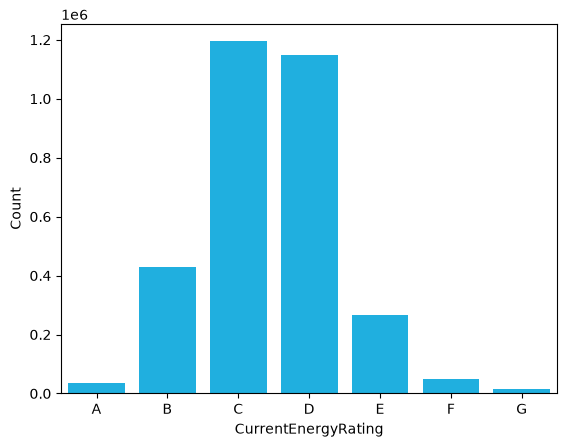

In [60]:
sns.barplot(x='CurrentEnergyRating',
            y='Count',
            data=er_current,
            color='deepskyblue')

<Axes: xlabel='PotentialEnergyRating', ylabel='Count'>

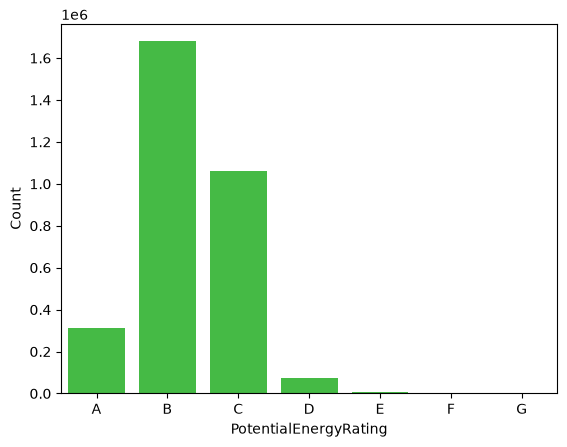

In [61]:
sns.barplot(x='PotentialEnergyRating',
            y='Count',
            data=er_potential,
            color='limegreen')

##### Current & potential combined

In [62]:
er_semid = er_current.copy()
er_semid = er_semid.rename(columns={'CurrentEnergyRating':'EnergyRating', 'Count':'Current'})
er_semid["Potential"] = er_potential["Count"]
display(er_semid)

,EnergyRating,Current,Potential
0,A,35602,312215
1,B,428908,1678850
2,C,1194114,1059759
3,D,1147567,74862
4,E,265634,8281
5,F,48757,1173
6,G,14793,235


In [63]:
print(er_semid["Current"].sum())
print(er_semid["Potential"].sum())

3135375
3135375


In [64]:
er_semid = er_semid.melt(
    id_vars='EnergyRating',
    value_vars=['Current', 'Potential'],
    var_name='Type',
    value_name='Count')
display(er_semid)

,EnergyRating,Type,Count
0,A,Current,35602
1,B,Current,428908
2,C,Current,1194114
3,D,Current,1147567
4,E,Current,265634
5,F,Current,48757
6,G,Current,14793
7,A,Potential,312215
8,B,Potential,1678850
9,C,Potential,1059759


<Axes: xlabel='EnergyRating', ylabel='Count'>

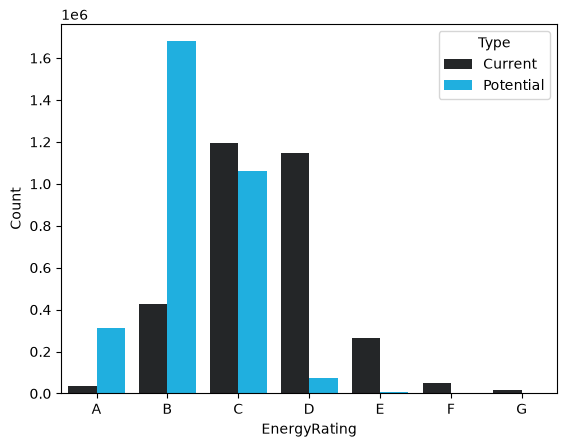

In [65]:
sns.barplot(x='EnergyRating',
            y='Count',
            hue='Type',
            data=er_semid,
            palette='dark:deepskyblue')

#### Mid-Terrace

In [66]:
type_midt = df_stats.iloc[df_stats["BuiltForm"]=="Mid-Terrace"]
display(type_midt)

,BuiltForm,CurrentEnergyRating,PotentialEnergyRating
5,Mid-Terrace,B,B
8,Mid-Terrace,C,B
9,Mid-Terrace,C,B
11,Mid-Terrace,C,C
14,Mid-Terrace,B,B
...,...,...,...
9916688,Mid-Terrace,C,C
9916689,Mid-Terrace,E,B
9916690,Mid-Terrace,B,B
9916691,Mid-Terrace,C,A


In [67]:
er_current = pd.DataFrame(type_midt["CurrentEnergyRating"].value_counts())
er_current = er_current.reset_index()
er_current = er_current.rename(columns={"count":"Count"})
er_current = er_current.sort_values(by="CurrentEnergyRating", ignore_index=True)

er_potential = pd.DataFrame(type_midt["PotentialEnergyRating"].value_counts())
er_potential = er_potential.reset_index()
er_potential = er_potential.rename(columns={"count":"Count"})
er_potential = er_potential.sort_values(by="PotentialEnergyRating", ignore_index=True)

print(er_current["Count"].sum())
print(er_potential["Count"].sum())

2854021
2854021


<Axes: xlabel='CurrentEnergyRating', ylabel='Count'>

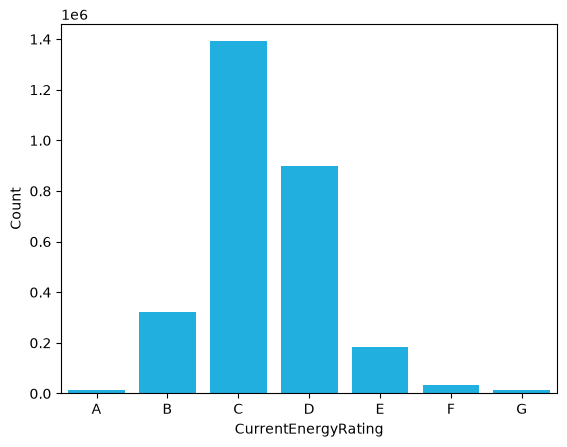

In [68]:
sns.barplot(x='CurrentEnergyRating',
            y='Count',
            data=er_current,
            color='deepskyblue')

<Axes: xlabel='PotentialEnergyRating', ylabel='Count'>

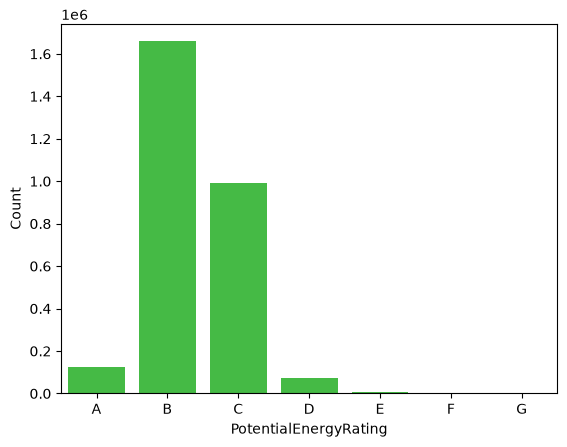

In [69]:
sns.barplot(x='PotentialEnergyRating',
            y='Count',
            data=er_potential,
            color='limegreen')

##### Current & potential combined

In [70]:
er_midt = er_current.copy()
er_midt = er_midt.rename(columns={'CurrentEnergyRating':'EnergyRating', 'Count':'Current'})
er_midt["Potential"] = er_potential["Count"]

print(er_midt["Current"].sum())
print(er_midt["Potential"].sum())

2854021
2854021


In [71]:
er_midt = er_midt.melt(
    id_vars='EnergyRating',
    value_vars=['Current', 'Potential'],
    var_name='Type',
    value_name='Count')
display(er_midt)

,EnergyRating,Type,Count
0,A,Current,13189
1,B,Current,320295
2,C,Current,1390570
3,D,Current,900628
4,E,Current,184577
5,F,Current,32429
6,G,Current,12333
7,A,Potential,125055
8,B,Potential,1658085
9,C,Potential,992242


<Axes: xlabel='EnergyRating', ylabel='Count'>

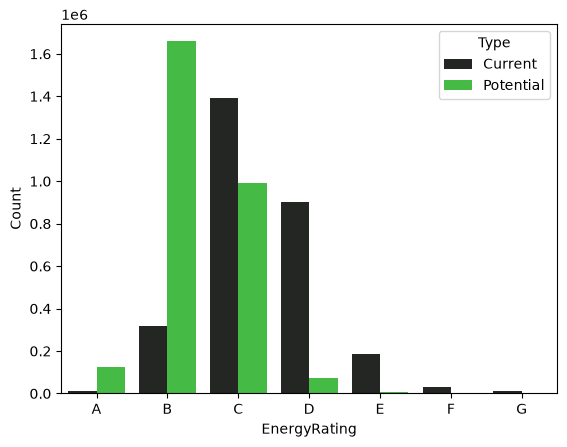

In [72]:
sns.barplot(x='EnergyRating',
            y='Count',
            hue='Type',
            data=er_midt,
            palette='dark:limegreen')

#### Detached

In [73]:
type_det = df_stats.iloc[df_stats["BuiltForm"]=="Detached"]
display(type_det)

,BuiltForm,CurrentEnergyRating,PotentialEnergyRating
7,Detached,D,C
17,Detached,E,C
18,Detached,C,B
29,Detached,E,C
32,Detached,E,B
...,...,...,...
9916677,Detached,E,C
9916680,Detached,E,D
9916681,Detached,C,C
9916699,Detached,E,C


In [74]:
er_current = pd.DataFrame(type_det["CurrentEnergyRating"].value_counts())
er_current = er_current.reset_index()
er_current = er_current.rename(columns={"count":"Count"})
er_current = er_current.sort_values(by="CurrentEnergyRating", ignore_index=True)

er_potential = pd.DataFrame(type_det["PotentialEnergyRating"].value_counts())
er_potential = er_potential.reset_index()
er_potential = er_potential.rename(columns={"count":"Count"})
er_potential = er_potential.sort_values(by="PotentialEnergyRating", ignore_index=True)

print(er_current["Count"].sum())
print(er_potential["Count"].sum())

2006869
2006869


<Axes: xlabel='CurrentEnergyRating', ylabel='Count'>

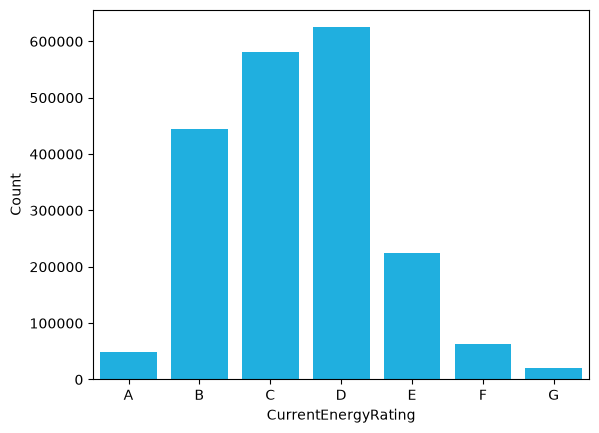

In [75]:
sns.barplot(x='CurrentEnergyRating',
            y='Count',
            data=er_current,
            color='deepskyblue')

<Axes: xlabel='PotentialEnergyRating', ylabel='Count'>

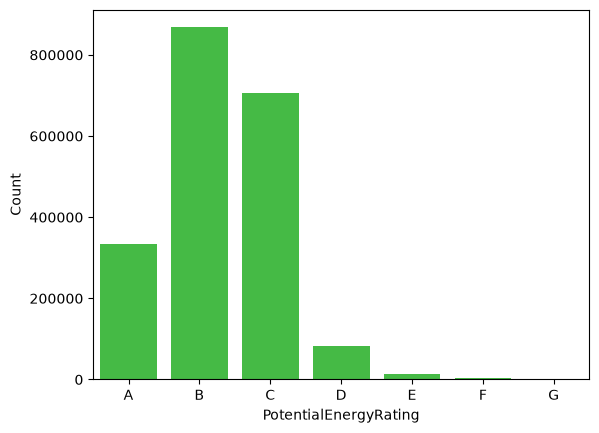

In [76]:
sns.barplot(x='PotentialEnergyRating',
            y='Count',
            data=er_potential,
            color='limegreen')

##### Current & potential combined

In [77]:
er_det = er_current.copy()
er_det = er_det.rename(columns={'CurrentEnergyRating':'EnergyRating', 'Count':'Current'})
er_det["Potential"] = er_potential["Count"]

print(er_det["Current"].sum())
print(er_det["Potential"].sum())

2006869
2006869


In [78]:
er_det = er_det.melt(
    id_vars='EnergyRating',
    value_vars=['Current', 'Potential'],
    var_name='Type',
    value_name='Count')
display(er_det)

,EnergyRating,Type,Count
0,A,Current,48871
1,B,Current,444161
2,C,Current,580538
3,D,Current,624616
4,E,Current,225065
5,F,Current,63379
6,G,Current,20239
7,A,Potential,333075
8,B,Potential,867490
9,C,Potential,705602


<Axes: xlabel='EnergyRating', ylabel='Count'>

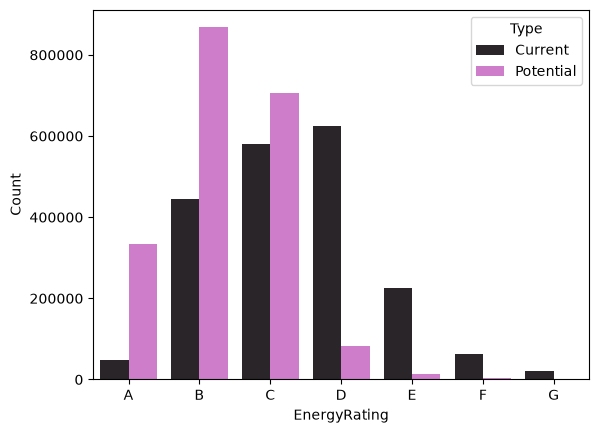

In [79]:
sns.barplot(x='EnergyRating',
            y='Count',
            hue='Type',
            data=er_det,
            palette='dark:orchid')

## Detecting outliers

In [80]:
df_outlier = pd.DataFrame(chunks[0]["FloorHeight"])
df_outlier = df_outlier.drop(df_outlier.index)
count_na = 0
for i in range(0, len(chunks)):
    chunk_select = pd.DataFrame(chunks[i][["FloorHeight"]])
    df_outlier = pd.concat([df_outlier, chunk_select])
    count_na += chunks[i]["FloorHeight"].isnull().sum()
display(df_outlier)

,FloorHeight
0,2.42
1,2.53
2,2.50
3,2.31
4,2.56
...,...
9916697,2.48
9916698,2.40
9916699,2.33
9916700,2.85


In [81]:
print(count_na)

98072


In [82]:
df_outlier.describe()

,FloorHeight
count,9.818630e+06
mean,2.427065e+00
std,2.487534e-01
min,0.000000e+00
25%,2.330000e+00
50%,2.400000e+00
75%,2.500000e+00
max,2.741000e+01


In [83]:
df_outlier_sorted = df_outlier.sort_values(by='FloorHeight', ascending=True)
display(df_outlier_sorted)

,FloorHeight
7480249,0.0
2323077,0.0
6066732,0.0
4519274,0.0
4733159,0.0
...,...
9916565,NaN
9916582,NaN
9916588,NaN
9916599,NaN


In [84]:
df_outlier_sorted['FloorHeight'] = df_outlier_sorted['FloorHeight'].astype(str)

In [85]:
df_outlier_sorted.value_counts()

FloorHeight
2.4            1302247
2.3             680014
2.5             470996
2.41            381206
2.35            325815
                ...   
20.7                 1
23.25                1
23.8                 1
24.82                1
27.41                1
Name: count, Length: 3278, dtype: int64

In [86]:
df_filter = chunks[0].iloc[chunks[0]['FloorHeight'] == 1]
display(df_filter)

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
117,Detached,32.0,7.6,5.0,England and Wales: before 1900,73,C,179,117,Single,...,40.0,82,B,House,"Pitched, no insulation (assumed)",owner-occupied,237,"Solid brick, as built, no insulation (assumed)",Fully double glazed,310055943
166,Semi-Detached,38.0,2.2,0.9,England and Wales: 1996-2002,68,D,219,91,Single,...,0.0,84,B,Bungalow,"Pitched, 200 mm loft insulation",rented (social),56,"Cavity wall, as built, insulated (assumed)",Fully double glazed,100100991305
379,End-Terrace,28.0,3.9,2.7,England and Wales: 1930-1949,69,C,171,123,Single,...,0.0,77,C,House,"Pitched, 100 mm loft insulation",owner-occupied,140,"Cavity wall, filled cavity",Fully double glazed,64021330
382,Semi-Detached,41.0,4.1,2.8,England and Wales: 1950-1966,69,C,233,155,Single,...,0.0,81,B,House,"Pitched, 200 mm loft insulation",rented (private),101,"Cavity wall, filled cavity",Fully double glazed,72032283
430,Mid-Terrace,32.0,2.2,1.9,England and Wales: 1900-1929,70,C,185,160,Single,...,0.0,73,C,Flat,(another dwelling above),rented (private),67,"Solid brick, as built, no insulation (assumed)",Fully double glazed,100100078109
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99420,Detached,54.0,7.2,2.9,England and Wales: 1950-1966,57,D,304,121,Single,...,0.0,82,B,Bungalow,"Roof room(s), no insulation (assumed)",owner-occupied,135,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,100030958467
99620,Detached,51.0,7.0,3.6,England and Wales: 1950-1966,52,E,194,86,Single,...,0.0,75,C,Bungalow,"Pitched, 100 mm loft insulation",owner-occupied,138,"Cavity wall, filled cavity",Fully double glazed,100060897377
99678,Semi-Detached,50.0,9.0,1.8,England and Wales: 1900-1929,40,E,161,-13,Single,...,50.0,78,C,House,"Pitched, 200 mm loft insulation",owner-occupied,179,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,100120001584
99928,Detached,50.0,5.1,2.2,England and Wales: 1991-1995,59,D,285,123,Single,...,0.0,81,B,House,"Pitched, 100 mm loft insulation",owner-occupied,101,"Cavity wall, as built, insulated (assumed)",Fully double glazed,100091129519


### Removing floor height below 1.0m

In [87]:
# Previous 9,818,630 rows
df_outlier = df_outlier.dropna()
display(df_outlier)

,FloorHeight
0,2.42
1,2.53
2,2.50
3,2.31
4,2.56
...,...
9916697,2.48
9916698,2.40
9916699,2.33
9916700,2.85


In [88]:
# New 9,815,476 rows
# Removed 3154 values
df_outlier = df_outlier[df_outlier['FloorHeight'] >= 1]
display(df_outlier)

,FloorHeight
0,2.42
1,2.53
2,2.50
3,2.31
4,2.56
...,...
9916697,2.48
9916698,2.40
9916699,2.33
9916700,2.85


In [89]:
df_outlier.describe()

,FloorHeight
count,9.815476e+06
mean,2.427844e+00
std,2.449636e-01
min,1.000000e+00
25%,2.330000e+00
50%,2.400000e+00
75%,2.500000e+00
max,2.741000e+01


In [90]:
display(chunks[0].loc[chunks[0]['FloorHeight'] < 1])

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
2250,NaN,6.0,0.4,0.4,2021,87,B,33,33,standard tariff,...,NaN,87,B,Flat,(other premises above),unknown,64,Average thermal transmittance 0.16 W/m²K,High performance glazing,<NA>
2797,Detached,26.0,4.0,2.8,2023,63,D,119,76,standard tariff,...,NaN,72,C,Bungalow,Average thermal transmittance 0.15 W/m²K,unknown,157,Average thermal transmittance 0.21 W/m²K,High performance glazing,10004884007
4127,NaN,23.0,1.2,1.2,2024,81,B,135,135,standard tariff,...,NaN,81,B,Flat,Average thermal transmittance 0.13 W/m²K,unknown,54,Average thermal transmittance 0.19 W/m²K,High performance glazing,10096061733
8698,NaN,4.0,0.3,0.3,2022,92,A,19,19,standard tariff,...,NaN,92,A,Flat,(other premises above),unknown,72,Average thermal transmittance 0.15 W/m²K,High performance glazing,10094746685
12036,NaN,15.0,0.5,0.5,2022,83,B,81,81,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,36,Average thermal transmittance 0.16 W/m²K,High performance glazing,10095507723
12540,NaN,22.0,0.8,0.8,2023,80,C,124,124,standard tariff,...,NaN,80,C,Flat,Average thermal transmittance 0.18 W/m²K,unknown,37,Average thermal transmittance 0.24 W/m²K,High performance glazing,10095639833
13271,Mid-Terrace,12.0,1.1,0.9,2022,90,B,67,55,standard tariff,...,NaN,91,B,House,Average thermal transmittance 0.10 W/m²K,unknown,96,Average thermal transmittance 0.19 W/m²K,High performance glazing,10095602530
15455,NaN,48.0,2.9,2.9,2021,58,D,283,283,standard tariff,...,NaN,58,D,Flat,(other premises above),unknown,60,Average thermal transmittance 0.23 W/m²K,Full secondary glazing,10094543877
15600,Detached,16.0,1.5,0.3,2023,83,B,94,18,standard tariff,...,NaN,94,A,House,Average thermal transmittance 0.14 W/m²K,unknown,89,Average thermal transmittance 0.18 W/m²K,High performance glazing,10096063733
18442,NaN,14.0,0.7,0.7,2022,84,B,77,77,standard tariff,...,NaN,84,B,Flat,Average thermal transmittance 0.11 W/m²K,unknown,50,Average thermal transmittance 0.20 W/m²K,High performance glazing,3455156574


In [91]:
# Better way to replace outliers with NA
chunks[0].loc[chunks[0]['FloorHeight'] < 1, 'FloorHeight'] = np.nan

In [92]:
display(chunks[0].loc[chunks[0]['FloorHeight'].isna()])

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
80,Detached,10.0,0.7,0.7,2021,88,B,57,57,standard tariff,...,NaN,88,B,Flat,(other premises above),unknown,71,Average thermal transmittance 0.16 W/m²K,High performance glazing,6735063
238,Detached,8.0,0.4,0.4,2021,85,B,44,44,standard tariff,...,NaN,85,B,Flat,(other premises above),unknown,54,Average thermal transmittance 0.18 W/m²K,High performance glazing,10095441100
244,Detached,7.0,0.6,0.6,2020,88,B,42,42,standard tariff,...,NaN,88,B,Flat,(other premises above),unknown,86,Average thermal transmittance 0.14 W/m²K,High performance glazing,12194127
245,Detached,10.0,0.5,0.5,2022,83,B,57,57,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,49,Average thermal transmittance 0.17 W/m²K,High performance glazing,10094448118
250,Detached,15.0,1.1,1.1,2019,83,B,84,84,standard tariff,...,NaN,83,B,Flat,Average thermal transmittance 0.15 W/m²K,unknown,76,Average thermal transmittance 0.24 W/m²K,High performance glazing,10095937159
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98917,Detached,13.0,0.9,0.9,2023,86,B,74,74,standard tariff,...,NaN,86,B,Flat,Average thermal transmittance 0.11 W/m²K,unknown,71,Average thermal transmittance 0.16 W/m²K,High performance glazing,10095746630
98919,Detached,7.0,0.5,0.5,2020,85,B,40,40,standard tariff,...,NaN,85,B,Flat,(other premises above),unknown,62,Average thermal transmittance 0.15 W/m²K,High performance glazing,10095440622
98941,NaN,18.0,0.9,0.9,2023,85,B,106,106,standard tariff,...,NaN,85,B,Flat,(other premises above),unknown,53,Average thermal transmittance 0.13 W/m²K,High performance glazing,10010234044
98987,Detached,22.0,0.9,0.9,2022,84,B,127,127,standard tariff,...,NaN,84,B,Flat,(other premises above),unknown,42,Average thermal transmittance 0.14 W/m²K,High performance glazing,38336160


In [93]:
for i in range(0, len(chunks)):
    # Better way to replace outliers with NA
    chunks[i].loc[chunks[i]['FloorHeight'] < 1, 'FloorHeight'] = np.nan

In [94]:
# Previous 98072 NA value count
# New 101226 NA value count
# 3154 removed (matches previous result)
df_outlier = pd.DataFrame(chunks[0]["FloorHeight"])
df_outlier = df_outlier.drop(df_outlier.index)
count_na = 0
for i in range(0, len(chunks)):
    chunk_select = pd.DataFrame(chunks[i][["FloorHeight"]])
    df_outlier = pd.concat([df_outlier, chunk_select])
    count_na += chunks[i]["FloorHeight"].isnull().sum()
display(df_outlier)

,FloorHeight
0,2.42
1,2.53
2,2.50
3,2.31
4,2.56
...,...
9916697,2.48
9916698,2.40
9916699,2.33
9916700,2.85


In [95]:
print(count_na)

101226


## Field name descriptions

FLAT_TOP_STOREY - Whether the flat is on the top floor of a building.

PHOTO_SUPPLY - Whether the property generates electricity from solar panels. The proportion of the roof area (%) covered by solar panels is assessed. 0% means that the property does not have solar panels.

NUMBER_HABITABLE_ROOMS - Number of habitable rooms, includes any living room, sitting room, dining room, bedroom, study and similar and non-separated conservatories. Non-habitable rooms are ancillary rooms and include hallways, stairs & landings, kitchens, utility rooms, bathrooms, cloakrooms, large storage cupboards, WCs, en-suites and any habitable room not having access to natural daylight.

MECHANICAL_VENTILATION - Describes the type of mechanical ventilation in the property, such as an extractor fan, positive input ventilation, or mechanical ventilation with heat recovery. 

ENVIRONMENT_IMPACT_CURRENT - An estimate of current carbon dioxide (CO?) emissions related to heating, lighting and hot water use. Rated on a scale of 1-92+. The higher the rating, the lower the emissions. The ratings are grouped into bands A-G  where A is best and G is worst.

In [96]:
chunks[0].head()

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
0,Semi-Detached,68.0,6.2,0.8,England and Wales: 1900-1929,40,E,385,47,Single,...,0.0,89,B,House,"Pitched, 75 mm loft insulation",owner-occupied,91,"Solid brick, as built, no insulation (assumed)",Fully double glazed,100050952
1,Semi-Detached,62.0,5.0,2.3,England and Wales: 1930-1949,56,D,349,159,Single,...,0.0,80,C,House,"Pitched, no insulation",owner-occupied,81,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,72031902
2,End-Terrace,18.0,1.1,1.1,2024,83,B,104,104,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,64,Average thermal transmittance 0.74 W/m²K,High performance glazing,38350188
3,Semi-Detached,15.0,0.8,0.8,2024,84,B,87,87,standard tariff,...,NaN,84,B,Flat,(other premises above),unknown,52,Average thermal transmittance 0.23 W/m²K,High performance glazing,10096173454
4,End-Terrace,50.0,4.9,2.9,England and Wales: 1900-1929,59,D,270,154,Single,...,0.0,77,C,House,"Pitched, 200 mm loft insulation",rented (private),99,"Solid brick, as built, no insulation (assumed)",Fully double glazed,<NA>


In [97]:
df_stats = pd.DataFrame(chunks[0][["MainFuel", "MainheatDescription"]])
df_stats = df_stats.drop(df_stats.index)
for i in range(0, len(chunks)):
    data_filter = pd.DataFrame(chunks[i][["MainFuel", "MainheatDescription"]])
    df_stats = pd.concat([df_stats, data_filter])
#df_stats = df_stats.dropna(axis=0, how='all')
display(df_stats)

,MainFuel,MainheatDescription
0,mains gas (not community),"Room heaters, mains gas"
1,mains gas (not community),"Boiler and radiators, mains gas"
2,"Electricity: electricity, unspecified tariff","Room heaters, electric"
3,Gas: mains gas,"Boiler and radiators, mains gas"
4,mains gas (not community),"Boiler and radiators, mains gas"
...,...,...
9916697,mains gas (not community),"Boiler and radiators, mains gas"
9916698,mains gas (not community),"Boiler and radiators, mains gas"
9916699,mains gas (not community),"Boiler and radiators, mains gas"
9916700,mains gas (not community),"Boiler and radiators, mains gas"


In [98]:
df_stats['MainFuel'].value_counts()

MainFuel
mains gas (not community)                                                                        6668072
electricity (not community)                                                                      1160264
Gas: mains gas                                                                                    822523
Electricity: electricity, unspecified tariff                                                      338344
oil (not community)                                                                               281965
mains gas (community)                                                                             272789
LPG (not community)                                                                                49671
To be used only when there is no heating/hot-water system or data is from a community network      29218
dual fuel - mineral + wood                                                                         17816
electricity (community)                       

In [99]:
df_stats['MainheatDescription'].value_counts()

MainheatDescription
Boiler and radiators, mains gas                                                                                    7296074
Room heaters, electric                                                                                              629772
Electric storage heaters                                                                                            505915
Community scheme                                                                                                    497073
Boiler and radiators, oil                                                                                           269821
                                                                                                                    ...   
Air source heat pump, Underfloor heating, pipes in screed above insulation, electric, Boiler And radiators, oil          1
Boiler and radiators, mains gas, Room heaters, LPG                                                                     

Most common main heating system - Boiler and radiators, mains gas

## Store dataset in parquet

In [100]:
chunks[0].head()

,BuiltForm,Co2EmissCurrPerFloorArea,Co2EmissionsCurrent,Co2EmissionsPotential,ConstructionAgeBand,CurrentEnergyEfficiency,CurrentEnergyRating,EnergyConsumptionCurrent,EnergyConsumptionPotential,EnergyTariff,...,PhotoSupply,PotentialEnergyEfficiency,PotentialEnergyRating,PropertyType,RoofDescription,Tenure,TotalFloorArea,WallsDescription,WindowsDescription,Uprn
0,Semi-Detached,68.0,6.2,0.8,England and Wales: 1900-1929,40,E,385,47,Single,...,0.0,89,B,House,"Pitched, 75 mm loft insulation",owner-occupied,91,"Solid brick, as built, no insulation (assumed)",Fully double glazed,100050952
1,Semi-Detached,62.0,5.0,2.3,England and Wales: 1930-1949,56,D,349,159,Single,...,0.0,80,C,House,"Pitched, no insulation",owner-occupied,81,"Cavity wall, as built, no insulation (assumed)",Fully double glazed,72031902
2,End-Terrace,18.0,1.1,1.1,2024,83,B,104,104,standard tariff,...,NaN,83,B,Flat,(other premises above),unknown,64,Average thermal transmittance 0.74 W/m²K,High performance glazing,38350188
3,Semi-Detached,15.0,0.8,0.8,2024,84,B,87,87,standard tariff,...,NaN,84,B,Flat,(other premises above),unknown,52,Average thermal transmittance 0.23 W/m²K,High performance glazing,10096173454
4,End-Terrace,50.0,4.9,2.9,England and Wales: 1900-1929,59,D,270,154,Single,...,0.0,77,C,House,"Pitched, 200 mm loft insulation",rented (private),99,"Solid brick, as built, no insulation (assumed)",Fully double glazed,<NA>


In [101]:
len(chunks[0].index)

100000

In [102]:
len(chunks[99].index)

16702

### Test conversion of first & last chunk to PyArrow table

In [103]:
pa_table = pa.Table.from_pandas(chunks[0])
print(pa_table.num_columns)
print(pa_table.num_rows)

35
100000


In [104]:
print(pa_table)

pyarrow.Table
BuiltForm: large_string
Co2EmissCurrPerFloorArea: double
Co2EmissionsCurrent: double
Co2EmissionsPotential: double
ConstructionAgeBand: large_string
CurrentEnergyEfficiency: int64
CurrentEnergyRating: large_string
EnergyConsumptionCurrent: int64
EnergyConsumptionPotential: int64
EnergyTariff: large_string
EnvironmentImpactCurrent: int16
EnvironmentImpactPotential: int16
ExtensionCount: int8
FlatTopStorey: large_string
FloorDescription: large_string
FloorHeight: double
FloorLevel: int32
InspectionDate: large_string
LodgementDate: large_string
MainFuel: large_string
MainheatDescription: large_string
MainsGasFlag: large_string
MechanicalVentilation: large_string
NumberHabitableRooms: int32
NumberOpenFireplaces: int16
PhotoSupply: double
PotentialEnergyEfficiency: int64
PotentialEnergyRating: large_string
PropertyType: large_string
RoofDescription: large_string
Tenure: large_string
TotalFloorArea: int64
WallsDescription: large_string
WindowsDescription: large_string
Uprn: int

In [105]:
pa_table = pa.Table.from_pandas(chunks[99])
print(pa_table.num_columns)
print(pa_table.num_rows)

35
16702


### Test equality between 2 methods for conversion of dataframes to parquet format

In [106]:
pa_table_list = []
for i in range(0, 9):
    pa_table_list.append(pa.Table.from_pandas(chunks[i]))
len(pa_table_list)

9

In [107]:
merged_table = pa.concat_tables(pa_table_list)
print(merged_table.num_columns)
print(merged_table.num_rows)

35
900000


In [108]:
print(merged_table)

pyarrow.Table
BuiltForm: large_string
Co2EmissCurrPerFloorArea: double
Co2EmissionsCurrent: double
Co2EmissionsPotential: double
ConstructionAgeBand: large_string
CurrentEnergyEfficiency: int64
CurrentEnergyRating: large_string
EnergyConsumptionCurrent: int64
EnergyConsumptionPotential: int64
EnergyTariff: large_string
EnvironmentImpactCurrent: int16
EnvironmentImpactPotential: int16
ExtensionCount: int8
FlatTopStorey: large_string
FloorDescription: large_string
FloorHeight: double
FloorLevel: int32
InspectionDate: large_string
LodgementDate: large_string
MainFuel: large_string
MainheatDescription: large_string
MainsGasFlag: large_string
MechanicalVentilation: large_string
NumberHabitableRooms: int32
NumberOpenFireplaces: int16
PhotoSupply: double
PotentialEnergyEfficiency: int64
PotentialEnergyRating: large_string
PropertyType: large_string
RoofDescription: large_string
Tenure: large_string
TotalFloorArea: int64
WallsDescription: large_string
WindowsDescription: large_string
Uprn: int

In [109]:
pq.write_table(merged_table, "processed/test1.parquet")

In [110]:
pqwriter = None
for i in range(0, 9):
    table = pa.Table.from_pandas(chunks[i])
    if i == 0:
        pqwriter = pq.ParquetWriter("processed/test2.parquet", table.schema)
    
    pqwriter.write_table(table)

if pqwriter:
    pqwriter.close()

In [111]:
table1 = pq.read_table("processed/test1.parquet")
#print(table1)

In [112]:
table2 = pq.read_table("processed/test2.parquet")
#print(table2)

In [113]:
pa.Table.equals(table1, table2)

True

### Convert entire dataset to parquet

In [114]:
pqwriter = None
for i in range(0, len(chunks)):
    table = pa.Table.from_pandas(chunks[i])
    if i == 0:
        pqwriter = pq.ParquetWriter("processed/epc-domestic.parquet", table.schema)
    
    pqwriter.write_table(table)

if pqwriter:
    pqwriter.close()

In [115]:
epc_processed = pq.read_table("processed/epc-domestic.parquet")
print(epc_processed.num_columns)
print(epc_processed.num_rows)

35
9916702


### Verify by comparing with chunked dataset

In [116]:
table2 = epc_processed.select([0])
print(table2)

pyarrow.Table
BuiltForm: large_string
----
BuiltForm: [["Semi-Detached","Semi-Detached","End-Terrace","Semi-Detached","End-Terrace",...,"Detached","Mid-Terrace","Semi-Detached","Semi-Detached","Mid-Terrace"],["Semi-Detached","Mid-Terrace","Semi-Detached","Semi-Detached","Semi-Detached",...,"End-Terrace","Detached","Mid-Terrace","Detached","End-Terrace"],...,["Mid-Terrace","Detached","Detached","Mid-Terrace","Mid-Terrace",...,"End-Terrace","End-Terrace","Detached","End-Terrace","Semi-Detached"],["Semi-Detached","Mid-Terrace","Semi-Detached","Mid-Terrace","Semi-Detached",...,"Semi-Detached","Semi-Detached","Detached","Enclosed End-Terrace","Detached"]]


In [117]:
print(len(chunks[0].columns))

35


In [118]:
df_col = chunks[0].iloc[:, 0]
df_col = df_col.drop(df_col.index)
for i in range(0, len(chunks)):
    chunk_select = chunks[i].iloc[:, 0]
    df_col = pd.concat([df_col, chunk_select])
table1 = pa.Table.from_pandas(pd.DataFrame(df_col))
display(df_col)

0                 Semi-Detached
1                 Semi-Detached
2                   End-Terrace
3                 Semi-Detached
4                   End-Terrace
                   ...         
9916697           Semi-Detached
9916698           Semi-Detached
9916699                Detached
9916700    Enclosed End-Terrace
9916701                Detached
Name: BuiltForm, Length: 9916702, dtype: str

In [119]:
pa.Table.equals(table1, table2)

True

In [120]:
counter = 0
for col in range(0, len(chunks[0].columns)):
    df_col = chunks[0].iloc[:, col]
    df_col = df_col.drop(df_col.index)

    for i in range(0, len(chunks)):
        chunk_select = chunks[i].iloc[:, col]
        df_col = pd.concat([df_col, chunk_select])

    table1 = pa.Table.from_pandas(pd.DataFrame(df_col))
    table2 = epc_processed.select([col])
    counter += 1

    if pa.Table.equals(table1, table2) != True:
        raise Exception("Error: Parquet file differs from processed dataframe")
print(counter)

35
